## Plot Abil Output

In [1]:
import cartopy.crs as ccrs
import cartopy as cart
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from pathlib import Path
from yaml import load, Loader
from datetime import datetime


In [2]:
def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "environment.yml").exists():
            return path
    raise FileNotFoundError("Could not find project root containing environment.yml")


PROJECT_ROOT = find_project_root()
CONFIG_PATH = PROJECT_ROOT / "1-phase example" / "regressor.yml"

with CONFIG_PATH.open('r') as f:
    model_config = load(f, Loader=Loader)

run_name = "pro_surf_reg"
current_date = datetime.today().strftime('%Y-%m-%d')
file = current_date + '_mean'
post_dir = PROJECT_ROOT / model_config['path_out'] / run_name / 'posts'
ds_mean = xr.open_dataset(post_dir / f"{file}.nc")
varname = 'Prochlorococcus'


### Create of map of surface pimary production in April

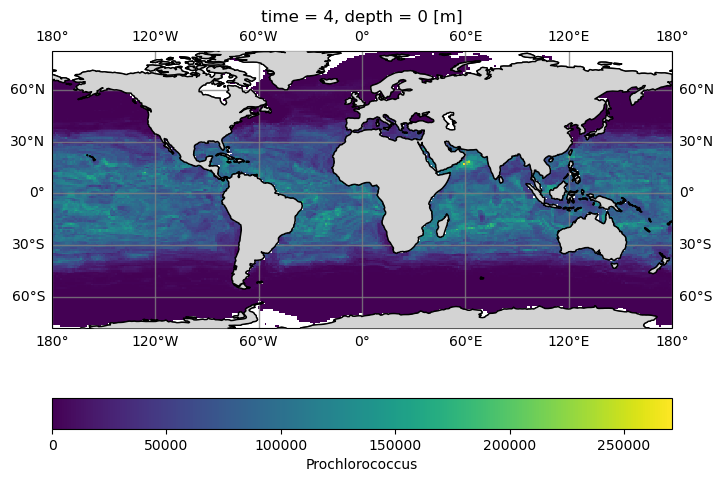

In [3]:
fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

# Add coastlines and land fill color
ax.coastlines()
ax.add_feature(cart.feature.LAND, 
               linewidth = 1, 
               zorder=3, 
               edgecolor='k', 
               facecolor="lightgray")

ax.gridlines(draw_labels=True, 
             linewidth=1,
             color='gray',
             alpha=0.8,
             linestyle='-',
             zorder=1
)
p = ds_mean[varname].sel(
    depth=0,
    time=4
    ).plot(
        x='lon',
        y='lat',
        transform=ccrs.PlateCarree(),
        add_colorbar=False,)


cbar = plt.colorbar(p, 
                    location='bottom', 
                    label="Prochlorococcus")

### Create map of depth integrated annual production

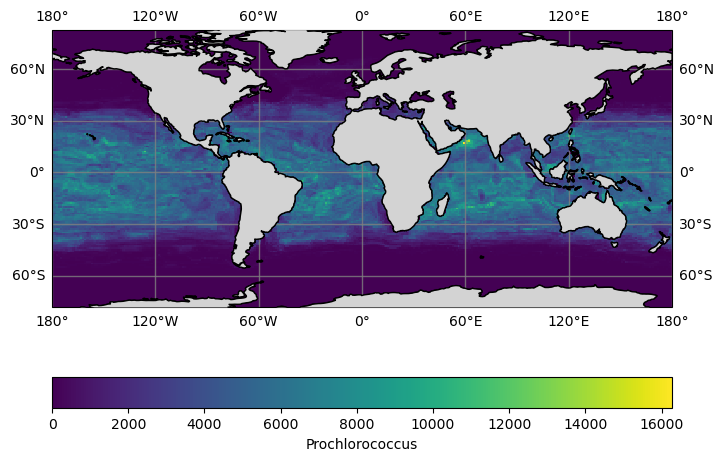

In [4]:
fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

# Add coastlines and land fill color
ax.coastlines()
ax.add_feature(cart.feature.LAND, 
               linewidth = 1, 
               zorder=3, 
               edgecolor='k', 
               facecolor="lightgray")

ax.gridlines(draw_labels=True, 
             linewidth=1,
             color='gray',
             alpha=0.8,
             linestyle='-',
             zorder=1
)

conversion_factor = 12.01e-3 # µmol to mg of C (C atomic weight)
depth_width = 5
depth_integrated_pp = ds_mean[varname].sum(dim=["depth"]).mean(dim="time") * depth_width * conversion_factor

p = depth_integrated_pp.plot(
        x='lon',
        y='lat',
        transform=ccrs.PlateCarree(),
        add_colorbar=False,)


cbar = plt.colorbar(p, 
                    location='bottom', 
                    label="Prochlorococcus")